# 01 · Social (Meta) geo holdout — design → holdout → readout

**Business question.** A US auto/home insurer spends on paid Social. Last-touch attribution credits Social with a large share of
quote starts, but how many of those quotes would have happened anyway? We pause Social in a *pipeline-selected* market and
measure what is lost against a synthetic control.

**Why this is the "first, rough-but-correct" test**
* Unit = a single county or a *bundle* of 2–3 adjacent counties inside a population band (to get enough volume).
* Design metric = Social's **share of quote starts** (last-touch) — the series Social spend moves most directly.
* Synthetic-control weights are fit on pre-period data and then **locked** — no refitting after launch.
* The holdout is **incomplete** (25% of spend keeps serving), the window is 8 weeks and the true lift is small, so the read
  is expected to be *directional*. The notebook says so rather than forcing significance.

Everything is synthetic with known ground truth, so every estimate is compared against the truth.

In [1]:
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
from incrlab.config import get_config
cfg = get_config()
print("seed", cfg.seed, "| small", cfg.small)
def show(name, module, width=900):
    display(Image(filename=str(ROOT / "reports" / "figures" / module / f"{name}.png"), width=width))

seed 20260 | small False


In [2]:
from incrlab.meta import pipeline as MP
S = MP.run_design(cfg)
st = S.st
print(f"region {st.region}; design weeks {st.design_start}-{st.design_end} (train to {st.train_end}); test weeks {st.test_start}-{st.test_end}")

region EM; design weeks 0-57 (train to 50); test weeks 58-65


## 1. Candidate markets
Candidates are single counties and bundles of adjacent counties whose combined population sits in the target band. A bundle is
treated as one unit: funnel counts are summed and rates recomputed from the sums (never averaged).

In [3]:
print(len(S.candidates), "candidate units")
S.candidates.head(10)

25 candidate units


,unit,members,size,pop,is_bundle
0,EM-C06,[EM-C06],1,"530,070.0000",False
1,EM-C13,[EM-C13],1,"404,801.0000",False
2,EM-C01+EM-C21,"[EM-C01, EM-C21]",2,"526,218.0000",True
3,EM-C03+EM-C07,"[EM-C03, EM-C07]",2,"593,701.0000",True
4,EM-C03+EM-C20,"[EM-C03, EM-C20]",2,"404,418.0000",True
5,EM-C07+EM-C18,"[EM-C07, EM-C18]",2,"511,579.0000",True
6,EM-C07+EM-C20,"[EM-C07, EM-C20]",2,"595,975.0000",True
7,EM-C09+EM-C11,"[EM-C09, EM-C11]",2,"411,486.0000",True
8,EM-C09+EM-C18,"[EM-C09, EM-C18]",2,"423,949.0000",True
9,EM-C09+EM-C21,"[EM-C09, EM-C21]",2,"539,622.0000",True


## 2. K-means sanity lens
Clustering counties on demographics + quote propensity is *exploratory only*: it checks that the treated market is not a
demographic outlier and that donors span similar clusters. It does not drive selection.

In [4]:
print("k =", S.kmeans["k"])
pd.Series(S.kmeans["labels"]).value_counts().sort_index().rename("counties per cluster")

k = 5


cluster
0    6
1    7
2    6
3    2
4    4
Name: counties per cluster, dtype: int64

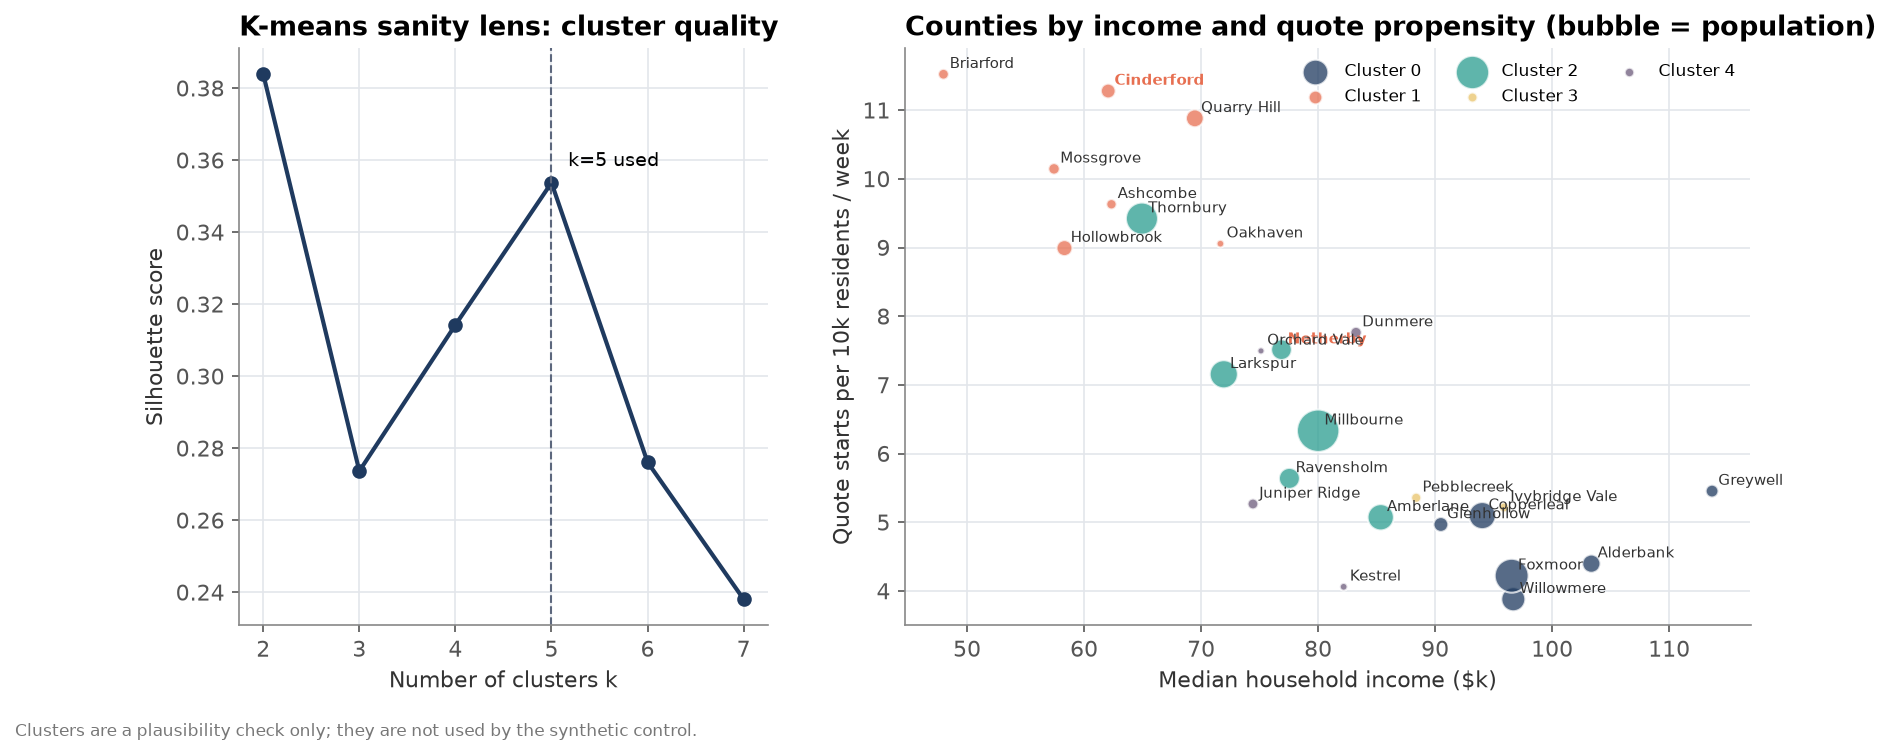

In [5]:
show("02_kmeans_sanity", "meta")

## 3. Locked-weight synthetic control, injected-lift validation, candidate scoring
For every candidate we fit synthetic-control weights on the training weeks (Social share of QS), freeze them, **inject** a known
5/10/15% loss into the pseudo-post weeks and check how well the locked weights recover it. Candidates are scored on pre-fit
RMSPE, donor concentration, injected-lift recovery and readout noise; hard filters reject units with an explicit reason.

In [6]:
S.ranked.head(12)

,unit,pre_rmspe,rel_rmspe,max_weight,hhi,neff,donor_count,detected_10,recovery_error,gap_sigma,gap_rho,mde_8wk,top_weights,weights,size,pop,s_fit,s_div,s_rec,s_noise,score,rejected_because,passes,rank
0,EM-C03+EM-C07,0.0138,0.0875,0.2539,0.1294,7.7262,11,0.1081,0.0081,0.0919,0.0000,0.1010,"EM-C10: 0.25, EM-C05: 0.12, EM-C04: 0.12, EM-C...","{'EM-C10': 0.2539, 'EM-C05': 0.1243, 'EM-C04':...",2,"593,701.0000",0.9600,1.0000,0.8385,0.7200,0.8896,,True,1
1,EM-C07+EM-C20,0.0146,0.0928,0.2677,0.1610,6.2116,10,0.1178,0.0178,0.0946,0.0000,0.1040,"EM-C22: 0.27, EM-C05: 0.22, EM-C06: 0.11, EM-C...","{'EM-C22': 0.2677, 'EM-C05': 0.2203, 'EM-C06':...",2,"595,975.0000",0.9200,1.0000,0.6446,0.6400,0.8111,,True,2
2,EM-C03+EM-C15+EM-C18,0.0173,0.1138,0.2436,0.1308,7.6430,12,0.1026,0.0026,0.0791,0.1632,0.1024,"EM-C05: 0.24, EM-C01: 0.15, EM-C24: 0.11, EM-C...","{'EM-C05': 0.2436, 'EM-C01': 0.1538, 'EM-C24':...",3,"470,451.0000",0.4400,1.0000,0.9477,0.9200,0.7749,,True,3
3,EM-C12+EM-C18+EM-C21,0.0171,0.1173,0.2105,0.1419,7.0482,10,0.1080,0.0080,0.1039,0.0000,0.1142,"EM-C10: 0.21, EM-C25: 0.19, EM-C03: 0.18, EM-C...","{'EM-C10': 0.2105, 'EM-C25': 0.1853, 'EM-C03':...",3,"474,539.0000",0.4000,1.0000,0.8403,0.4400,0.6381,,True,4
4,EM-C07+EM-C18,0.0163,0.1047,0.2203,0.1269,7.8810,11,0.1348,0.0348,0.1148,0.0000,0.1262,"EM-C22: 0.22, EM-C03: 0.15, EM-C23: 0.14, EM-C...","{'EM-C22': 0.2203, 'EM-C03': 0.1495, 'EM-C23':...",2,"511,579.0000",0.8400,1.0000,0.3036,0.2800,0.6259,,True,5
5,EM-C03+EM-C04+EM-C18,0.0174,0.1109,0.3136,0.1922,5.2028,9,0.1385,0.0385,0.0835,0.0399,0.0955,"EM-C10: 0.31, EM-C07: 0.25, EM-C01: 0.09, EM-C...","{'EM-C10': 0.3136, 'EM-C07': 0.2532, 'EM-C01':...",3,"414,031.0000",0.6000,0.8671,0.2304,0.8400,0.6090,,True,6
6,EM-C03+EM-C18+EM-C21,0.0167,0.1122,0.3901,0.2244,4.4570,8,0.1240,0.0240,0.0965,0.0240,0.1086,"EM-C10: 0.39, EM-C01: 0.18, EM-C11: 0.14, EM-C...","{'EM-C10': 0.3901, 'EM-C01': 0.1809, 'EM-C11':...",3,"554,645.0000",0.5200,0.7428,0.5202,0.6000,0.5806,,True,7
7,EM-C09+EM-C11+EM-C18,0.0174,0.1117,0.2154,0.1363,7.3376,10,0.0719,0.0281,0.1129,0.0000,0.1241,"EM-C23: 0.22, EM-C08: 0.19, EM-C01: 0.14, EM-C...","{'EM-C23': 0.2154, 'EM-C08': 0.1872, 'EM-C01':...",3,"530,436.0000",0.5600,1.0000,0.4387,0.3600,0.5777,,True,8
8,EM-C09+EM-C21,0.0188,0.1276,0.3010,0.1852,5.4008,9,0.0853,0.0147,0.1255,0.0000,0.1379,"EM-C19: 0.30, EM-C01: 0.23, EM-C05: 0.12, EM-C...","{'EM-C19': 0.301, 'EM-C01': 0.2262, 'EM-C05': ...",2,"539,622.0000",0.2800,0.9001,0.7050,0.1600,0.4863,,True,9
9,EM-C03+EM-C15+EM-C20,0.0162,0.1057,0.3558,0.1736,5.7593,13,0.0872,0.0128,0.0767,0.0000,0.0843,"EM-C05: 0.36, EM-C01: 0.11, EM-C18: 0.10, EM-C...","{'EM-C05': 0.3558, 'EM-C01': 0.1121, 'EM-C18':...",3,"554,847.0000",0.8000,0.9599,0.7432,0.9600,0.8498,"donor count 13 outside [3, 12]",False,10


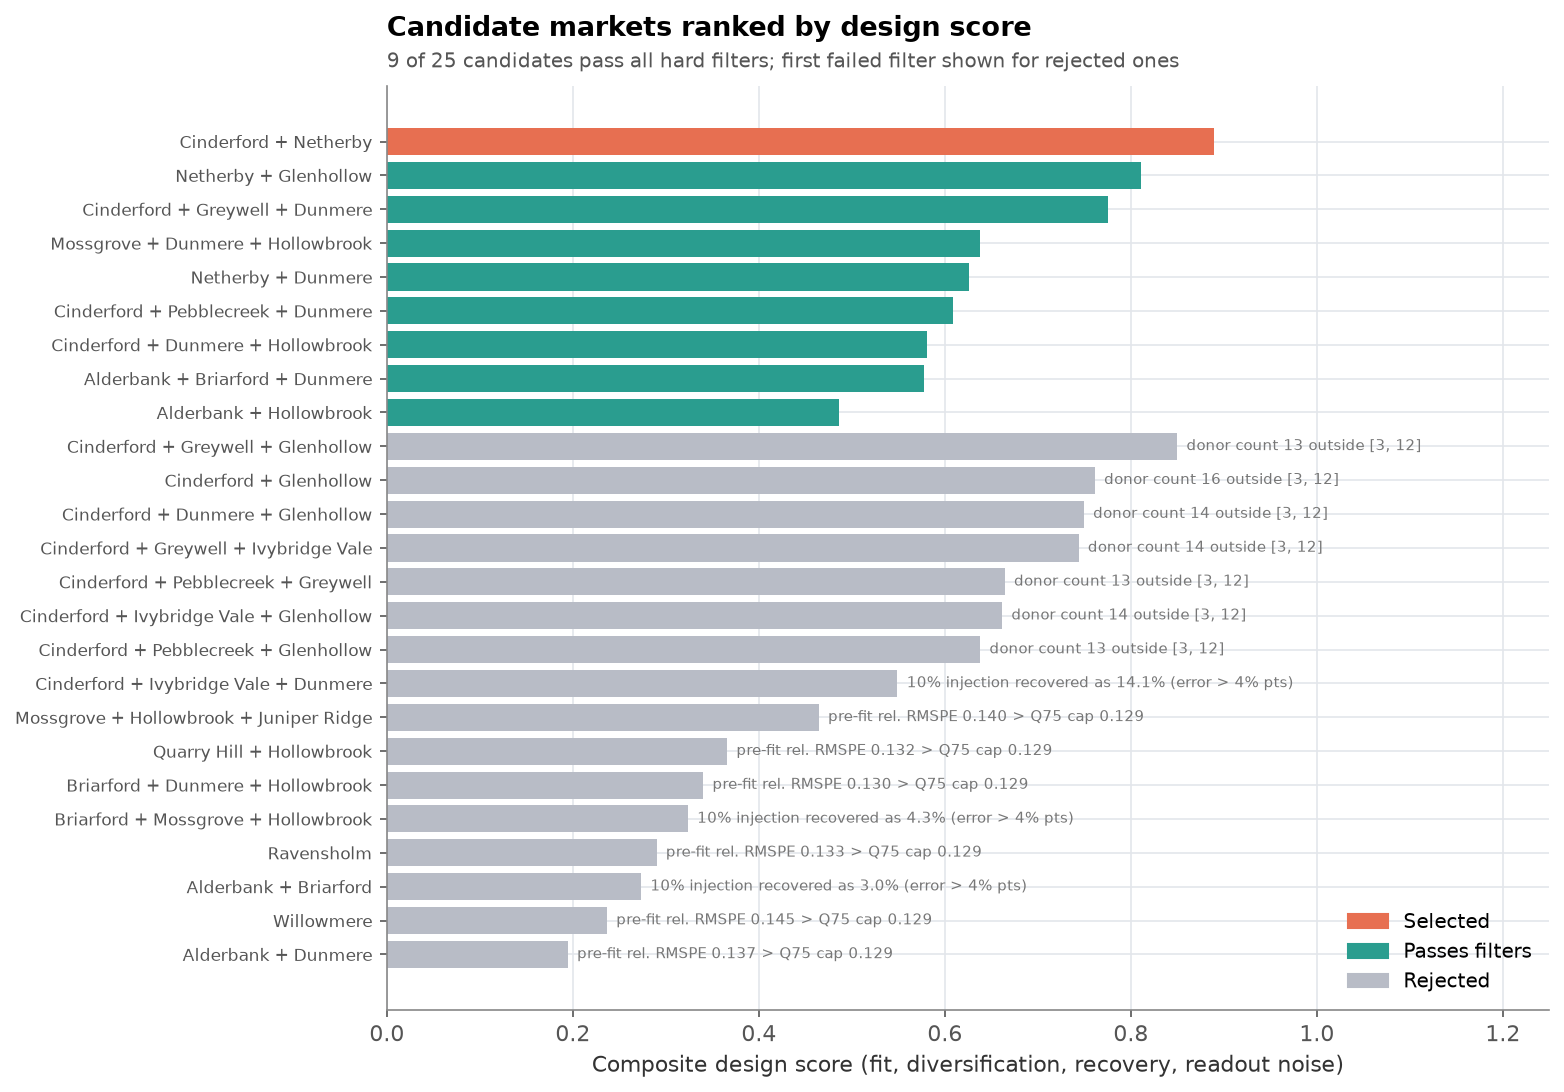

In [7]:
show("03_candidate_ranking", "meta")

In [8]:
print("Selected:", S.unit, "-", S.selection["reason"])
print("Locked donor weights:")
print(S.dfit.weights[S.dfit.weights > 0].sort_values(ascending=False).round(3).to_string())

Selected: EM-C03+EM-C07 - top-ranked candidate passing filters and jackknife
Locked donor weights:
EM-C10   0.2540
EM-C05   0.1240
EM-C04   0.1170
EM-C11   0.1040
EM-C08   0.0870
EM-C12   0.0720
EM-C24   0.0700
EM-C01   0.0520
EM-C21   0.0480
EM-C18   0.0430
EM-C02   0.0200
EM-C14   0.0060
EM-C17   0.0020


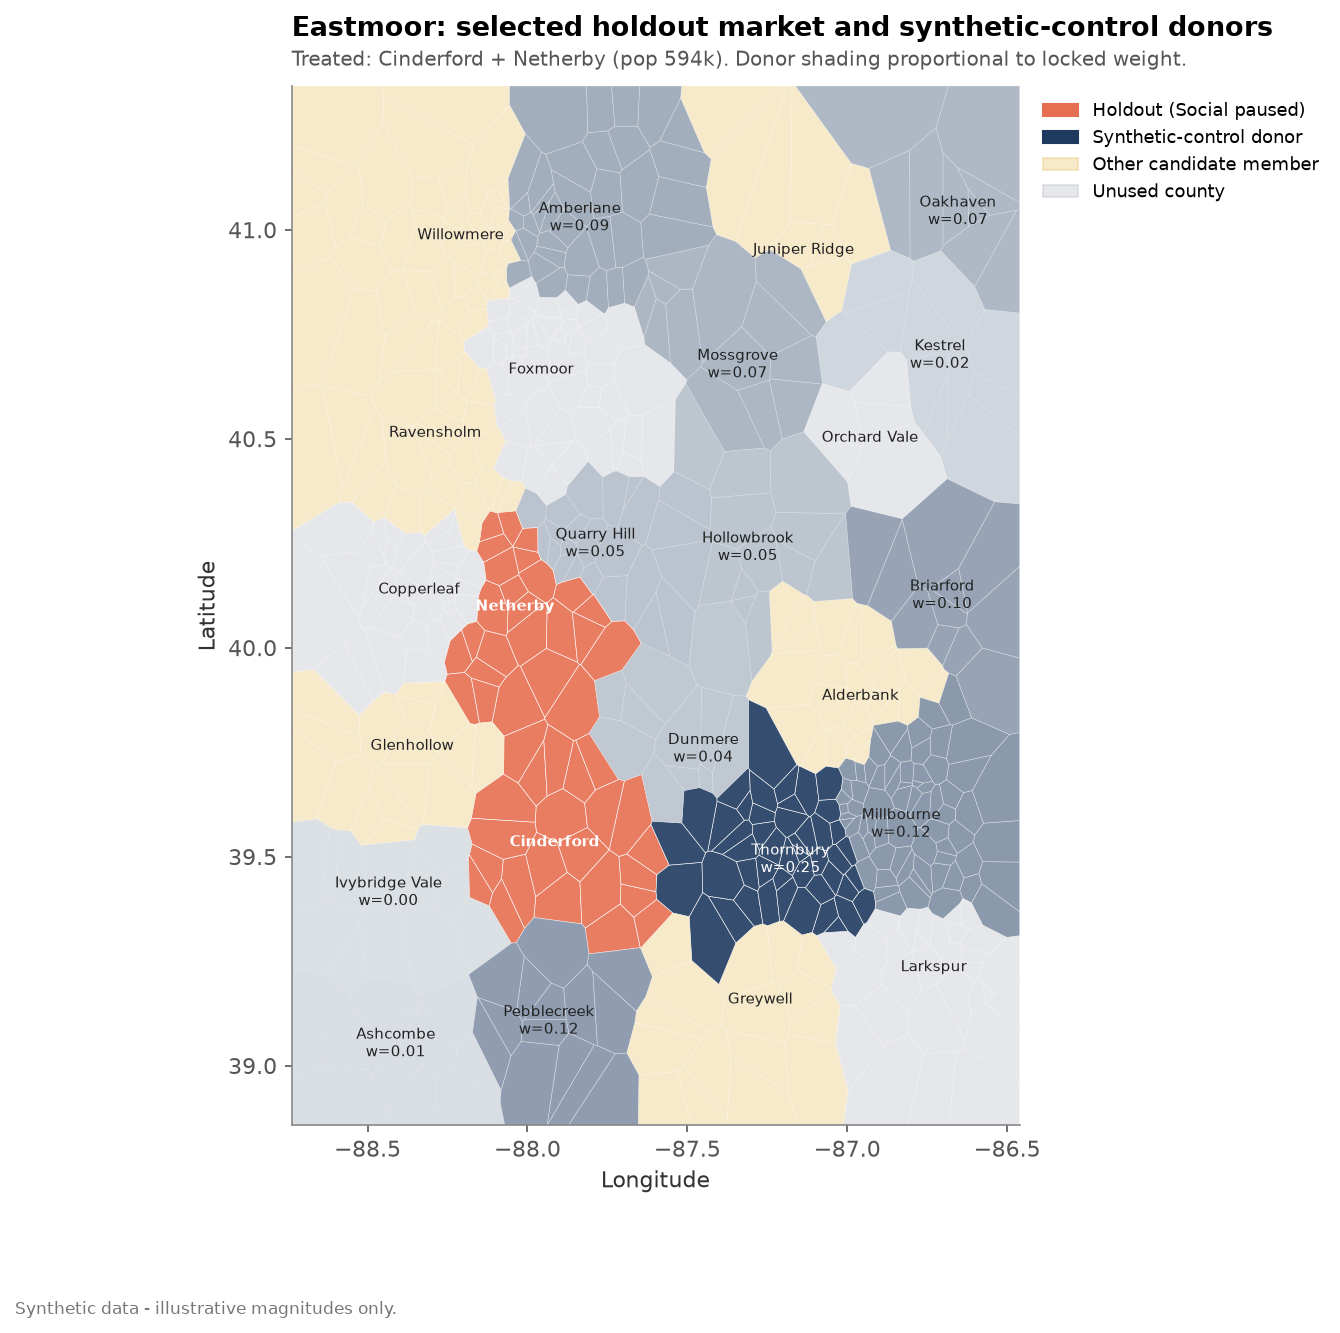

In [9]:
show("01_market_map", "meta", 650)

In [10]:
S.validation[S.validation["unit"] == S.unit]

,unit,metric,injected,detected,error,abs_error,natural_gap
0,EM-C03+EM-C07,qs,0.0500,0.0585,0.0085,0.0085,0.0090
1,EM-C03+EM-C07,qs,0.1000,0.1081,0.0081,0.0081,0.0090
2,EM-C03+EM-C07,qs,0.1500,0.1576,0.0076,0.0076,0.0090


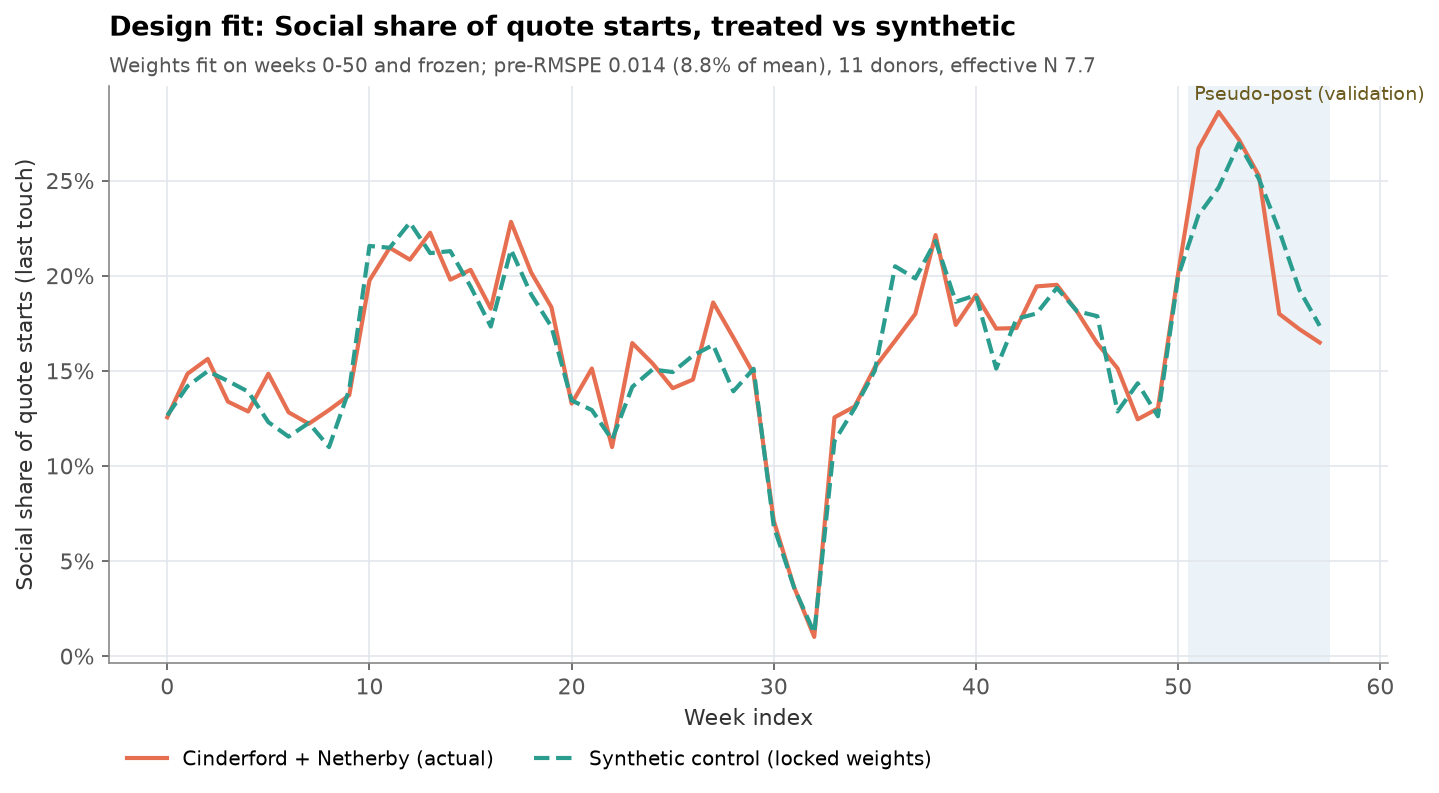

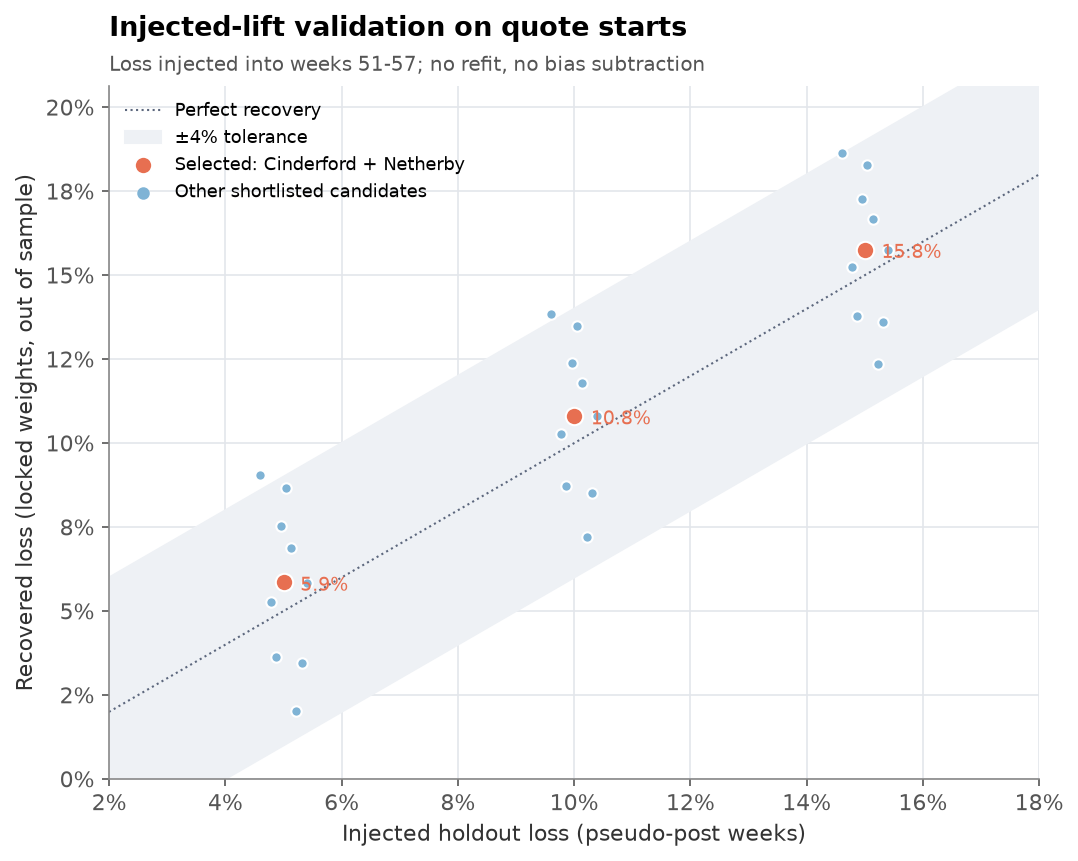

In [11]:
show("04_design_fit_share", "meta"); show("05_injected_lift_recovery", "meta")

Cross-check against `pysyncon`: donor weights differ (the objective is nearly flat across donor mixes) but the synthetic
paths and recovered lifts agree — which is what matters for the readout.

In [12]:
{k: v for k, v in S.pysyncon.items() if k in ("available", "pre_rmspe", "detected_10")}

{'available': True,
 'pre_rmspe': {'locked_design': 0.013806414695631153,
  'in_house_nested_v': 0.013607661221589672,
  'pysyncon': 0.017347737331860895},
 'detected_10': {'locked_design': 0.1080771719676747,
  'in_house_nested_v': 0.11303066036928698,
  'pysyncon': 0.10845639115835075}}

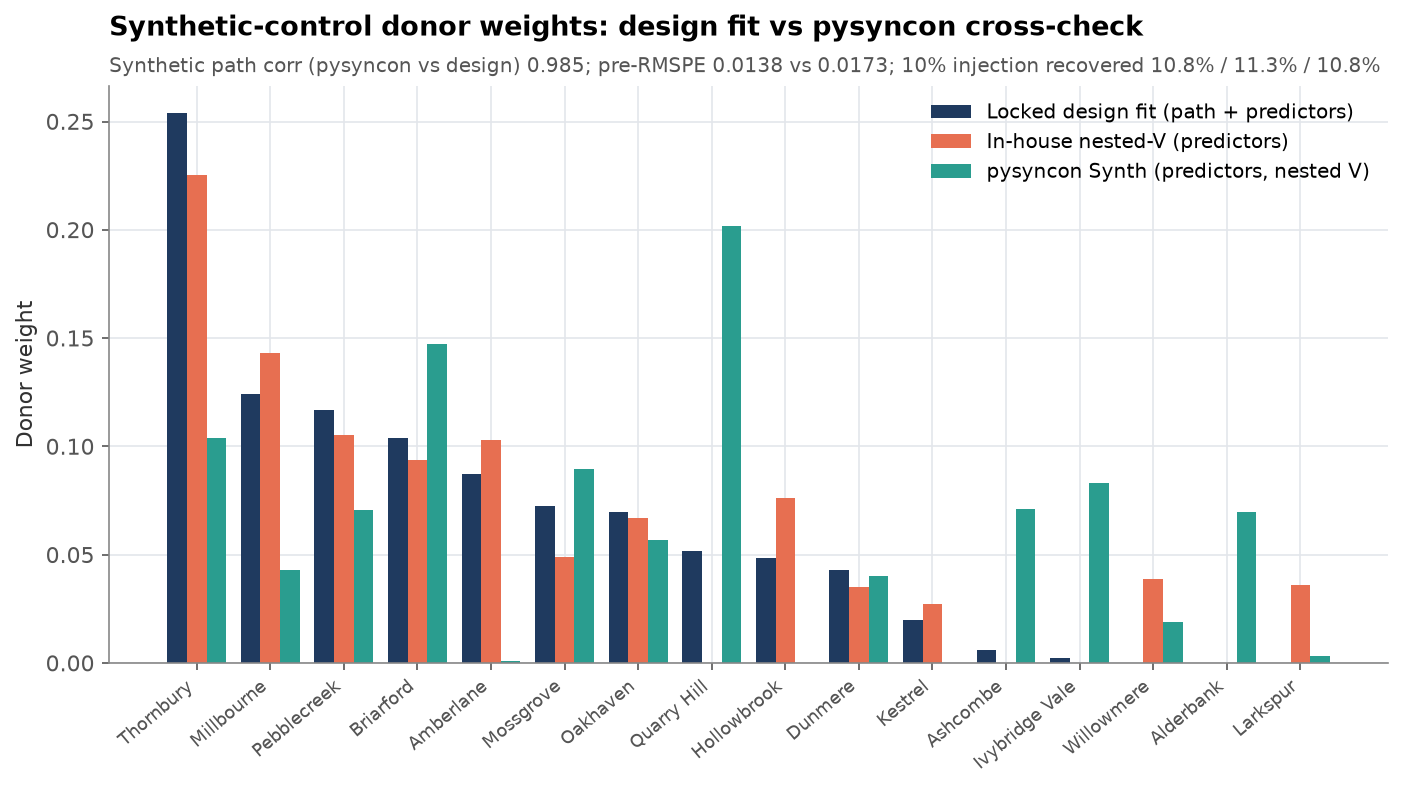

In [13]:
show("06_donor_weights_pysyncon", "meta")

## 4. Power: how big a Social effect can 8 weeks detect?
Closed-form DiD power from the sd of the weekly treated-vs-synthetic gap (one-sided α = 0.10, 80% power, AR(1)-adjusted),
checked against a simulation that injects lifts into real pre-period weeks.

In [14]:
print(f"weekly gap sd {S.noise['sigma']:.3f}, rho {S.noise['rho']:.2f}")
display(S.weeks_to_power)
pd.DataFrame(S.power_sim).T

weekly gap sd 0.092, rho 0.00


,lift,weeks_to_80
0,0.0300,NaN
1,0.0500,NaN
2,0.0750,NaN
3,0.1000,9.0000
4,0.1500,3.0000
5,0.2000,2.0000


,power,empirical_size,n_sims,lift,n_pre,n_post,critical_lift
0.0500,0.4267,0.0667,300.0000,0.0500,7.0000,8.0000,0.0610
0.1000,0.8667,0.0667,300.0000,0.1000,7.0000,8.0000,0.0610
0.1500,0.9833,0.0667,300.0000,0.1500,7.0000,8.0000,0.0610


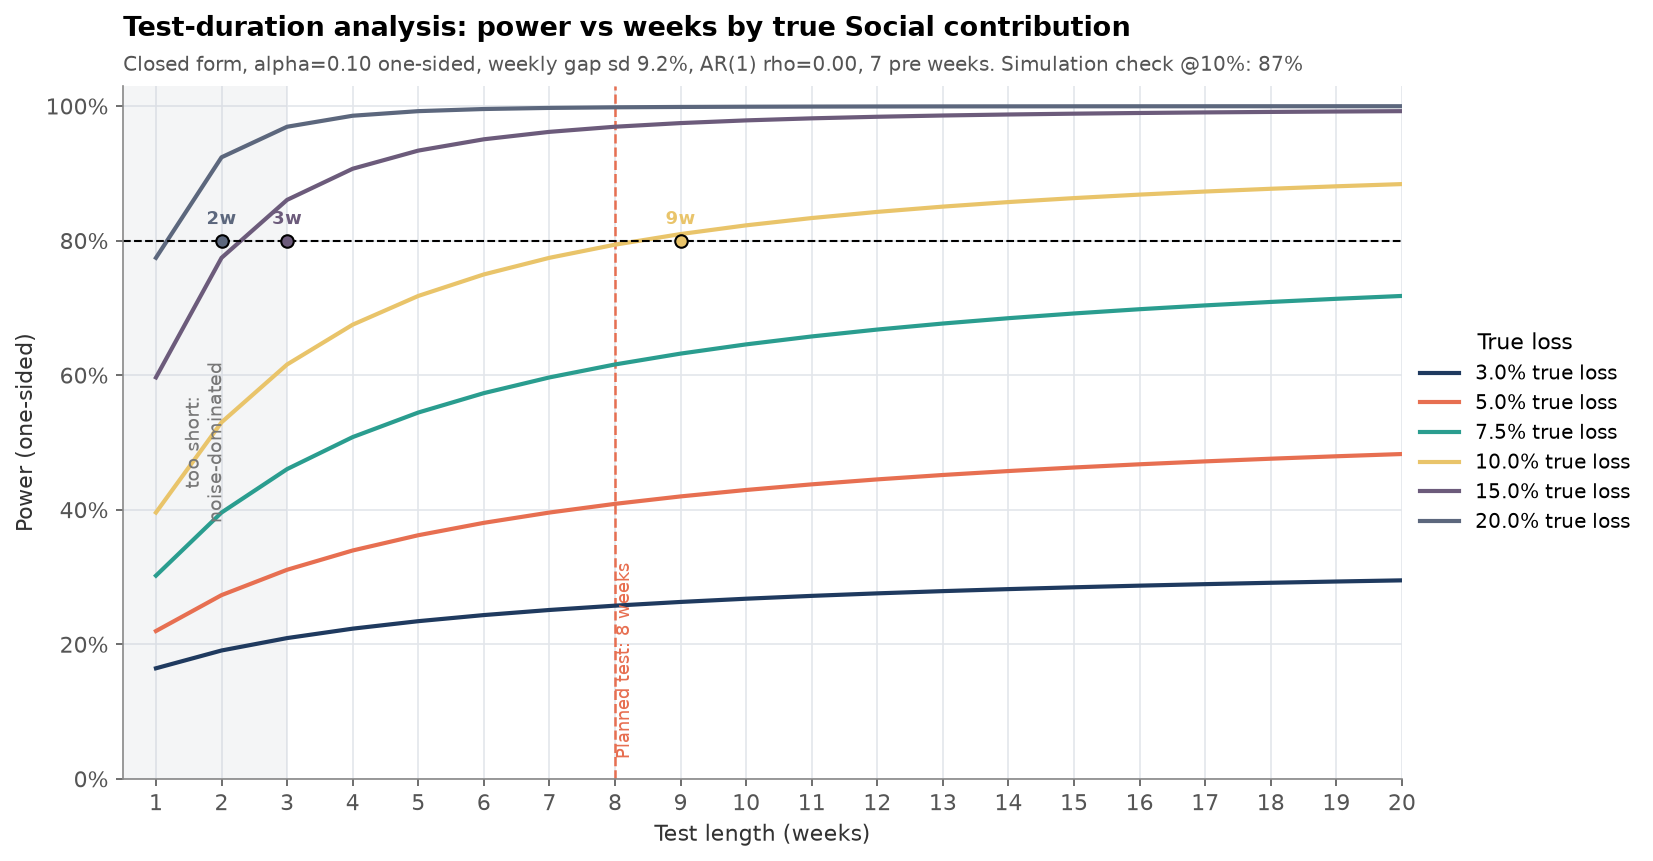

In [15]:
show("07_power_curve", "meta")

## 5. Jackknife: is the design driven by one donor?
Drop each active donor in turn, refit, rerun the 10% injection. Stable = recovery moves < 3pp and pre-RMSPE < 2×.

In [16]:
S.jackknife

,unit,dropped,dropped_weight,detected_10,change_pp,pre_rmspe,rmspe_ratio,neff,stable
0,EM-C03+EM-C07,(none),0.0000,0.1081,0.0000,0.0138,1.0000,7.7262,True
1,EM-C03+EM-C07,EM-C10,0.2539,0.1106,0.0025,0.0142,1.0282,8.7147,True
2,EM-C03+EM-C07,EM-C05,0.1243,0.1114,0.0034,0.0139,1.0062,6.7891,True
3,EM-C03+EM-C07,EM-C04,0.1168,0.1128,0.0047,0.0150,1.0865,5.4062,True
4,EM-C03+EM-C07,EM-C11,0.1041,0.0920,-0.0160,0.0143,1.0382,5.7709,True
5,EM-C03+EM-C07,EM-C08,0.0871,0.1078,-0.0003,0.0139,1.0095,7.5716,True
6,EM-C03+EM-C07,EM-C12,0.0723,0.1070,-0.0011,0.0139,1.0079,6.6164,True
7,EM-C03+EM-C07,EM-C24,0.0699,0.1145,0.0064,0.0142,1.0291,6.1976,True
8,EM-C03+EM-C07,EM-C01,0.0519,0.1102,0.0021,0.0138,0.9982,6.6869,True
9,EM-C03+EM-C07,EM-C21,0.0484,0.1082,0.0001,0.0139,1.0091,7.0589,True


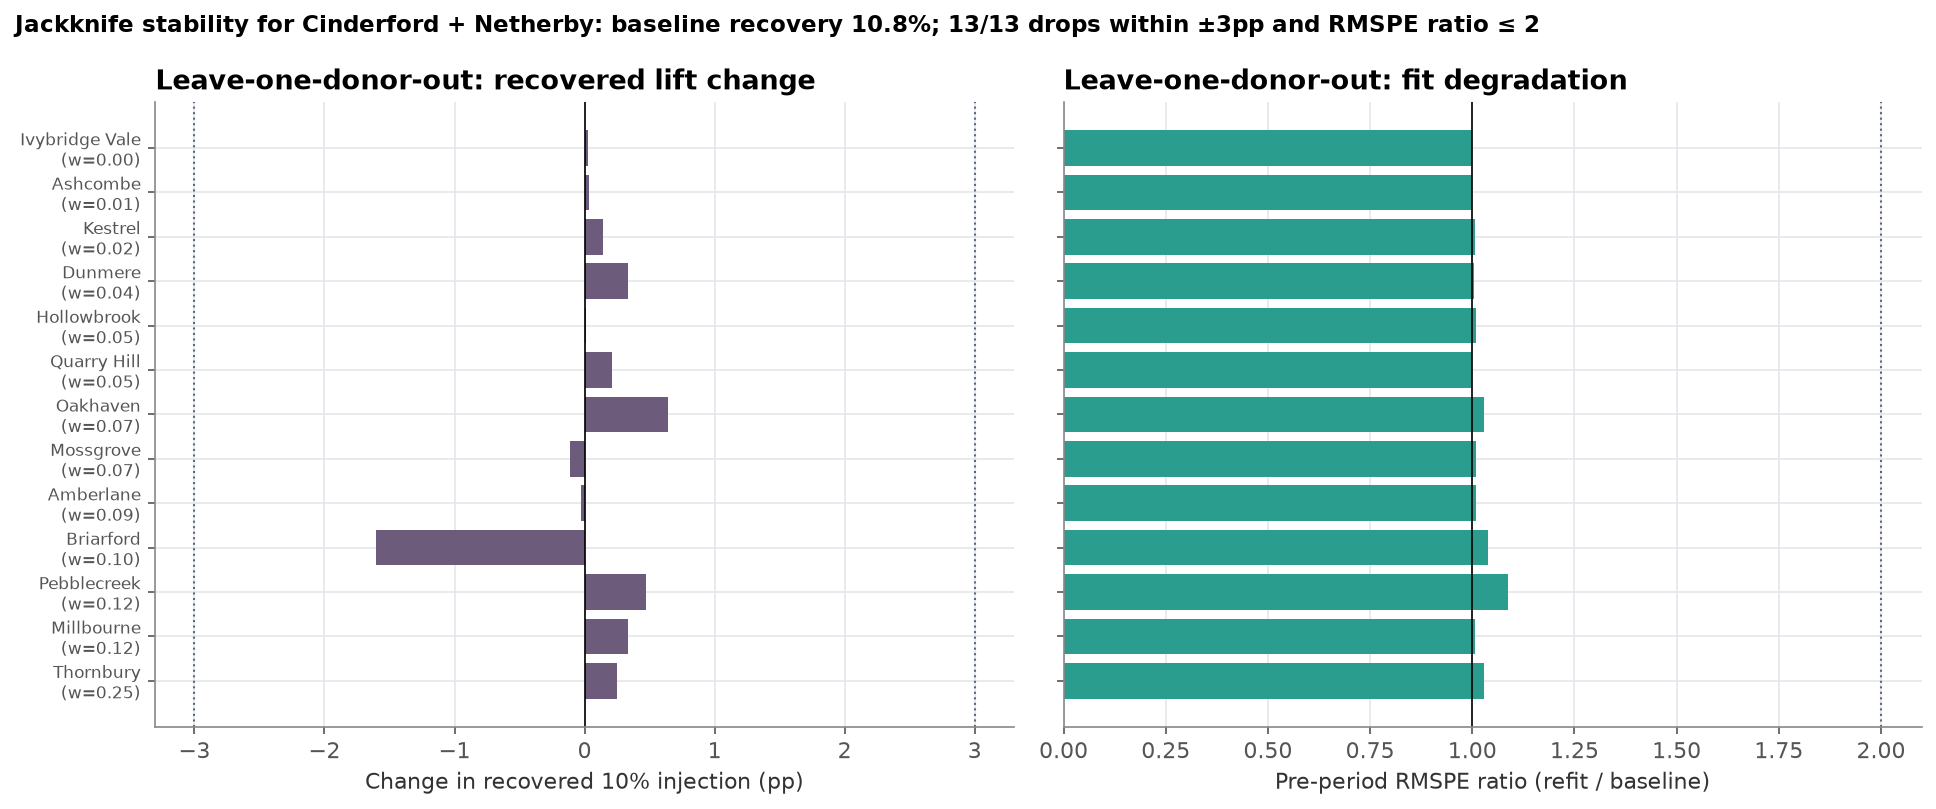

In [17]:
show("08_jackknife_stability", "meta")

## 6. Launch and readout
The holdout is applied to the selected unit through the scenario runner (true adstock + Hill response, 25% leakage).
Three estimators read the 8-week window against the **locked** synthetic control:
* **DiD with week fixed effects + HC1 robust SE** (primary),
* **ratio DiD** (cf = treated_pre × synthetic_post / synthetic_pre) with bootstrap CI,
* **synthetic-control gap** with an **in-space placebo** permutation p-value.

Lift sign: positive = Social contribution (volume lost while paused).

In [18]:
S = MP.run_readout(S)
tab = MP.estimates_table(S)
tab[["method", "metric", "estimate", "ci_low", "ci_high", "p_value", "truth", "error_pp", "ci_covers_truth"]]

,method,metric,estimate,ci_low,ci_high,p_value,truth,error_pp,ci_covers_truth
0,did_week_fe_hc1,qs,0.0268,-0.0342,0.0879,0.4501,0.0418,-0.0149,True
1,did_week_fe_hc1,rated,0.0220,-0.0420,0.0860,0.5531,0.0417,-0.0197,True
2,did_week_fe_hc1,sales,0.0481,-0.0857,0.1819,0.5354,0.0472,0.0009,True
3,ratio_did,qs,0.0288,-0.0258,0.0823,NaN,0.0418,-0.0130,True
4,ratio_did,rated,0.0233,-0.0349,0.0788,NaN,0.0417,-0.0183,True
5,ratio_did,sales,0.0493,-0.0699,0.1539,NaN,0.0472,0.0021,True
6,synthetic_control_gap,qs,0.0363,NaN,NaN,0.3750,0.0418,-0.0055,None
7,synthetic_control_gap,rated,0.0355,NaN,NaN,0.3333,0.0417,-0.0062,None
8,synthetic_control_gap,sales,0.0558,NaN,NaN,0.3333,0.0472,0.0085,None


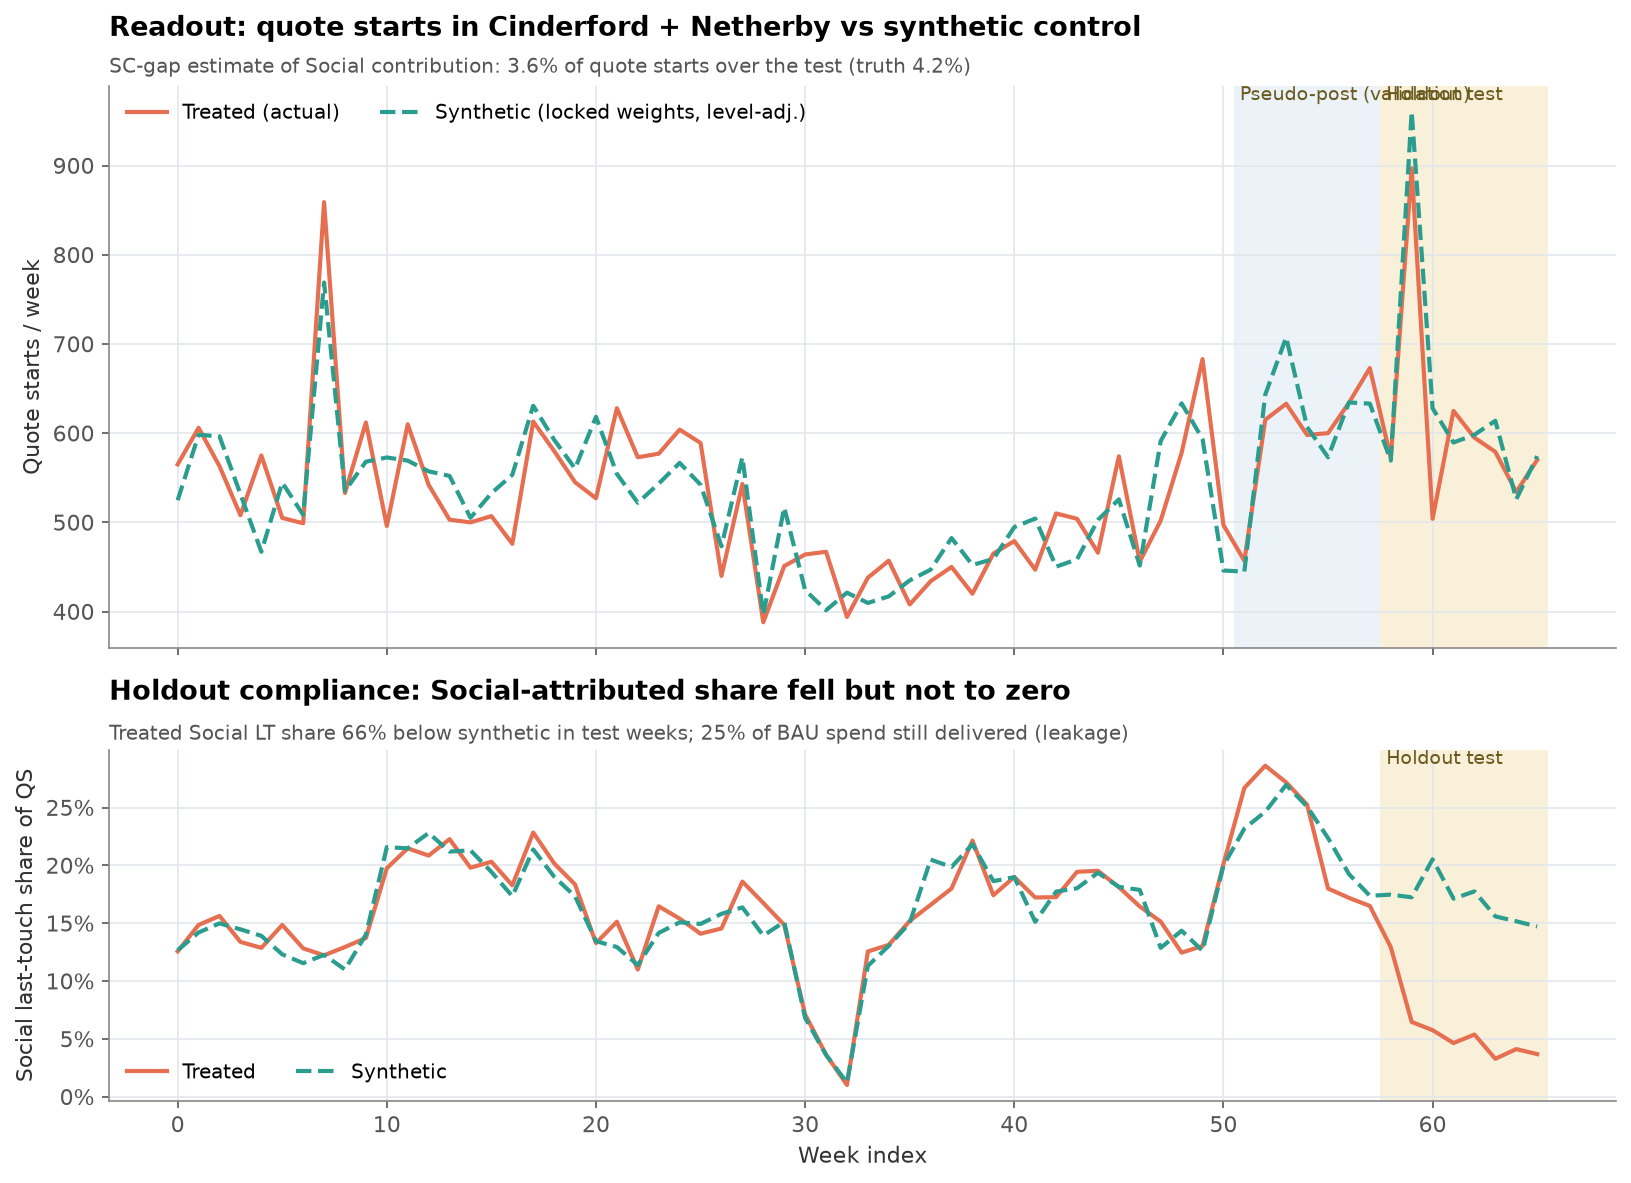

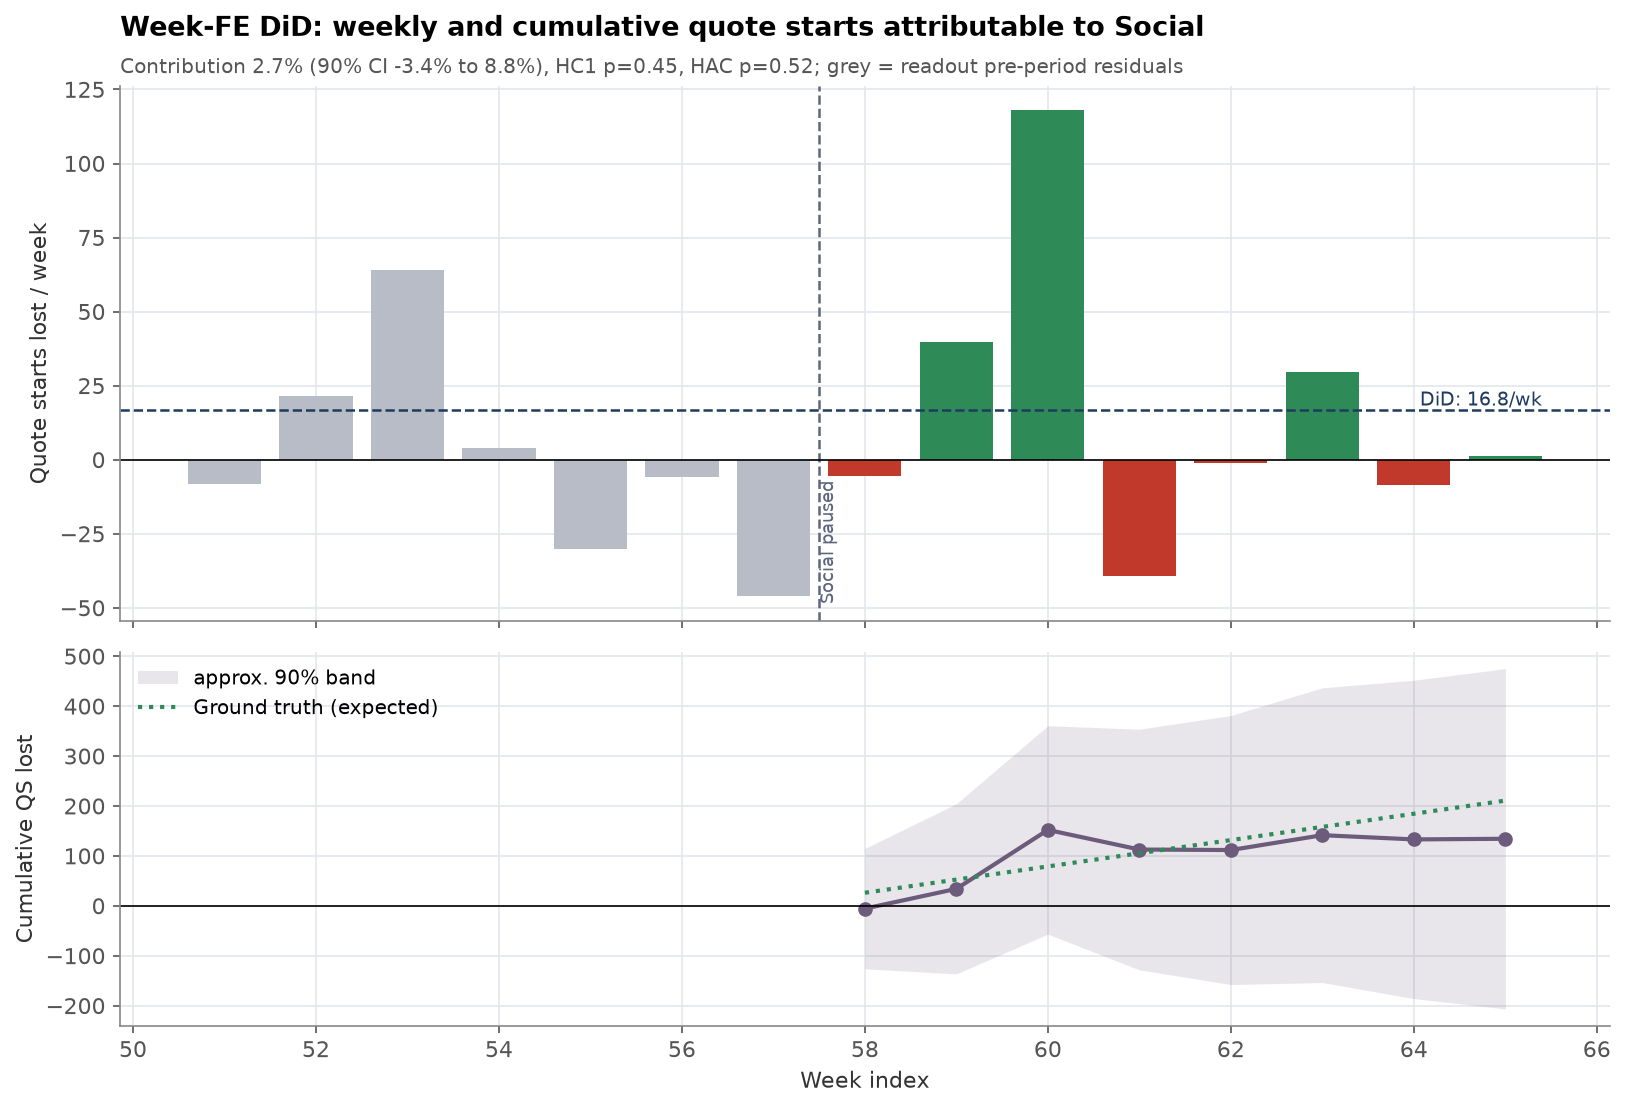

In [19]:
show("09_readout_treated_vs_synthetic", "meta"); show("10_did_weekly_cumulative", "meta")

{'qs': 0.375, 'rated': 0.333, 'sales': 0.333} | min attainable p 0.042


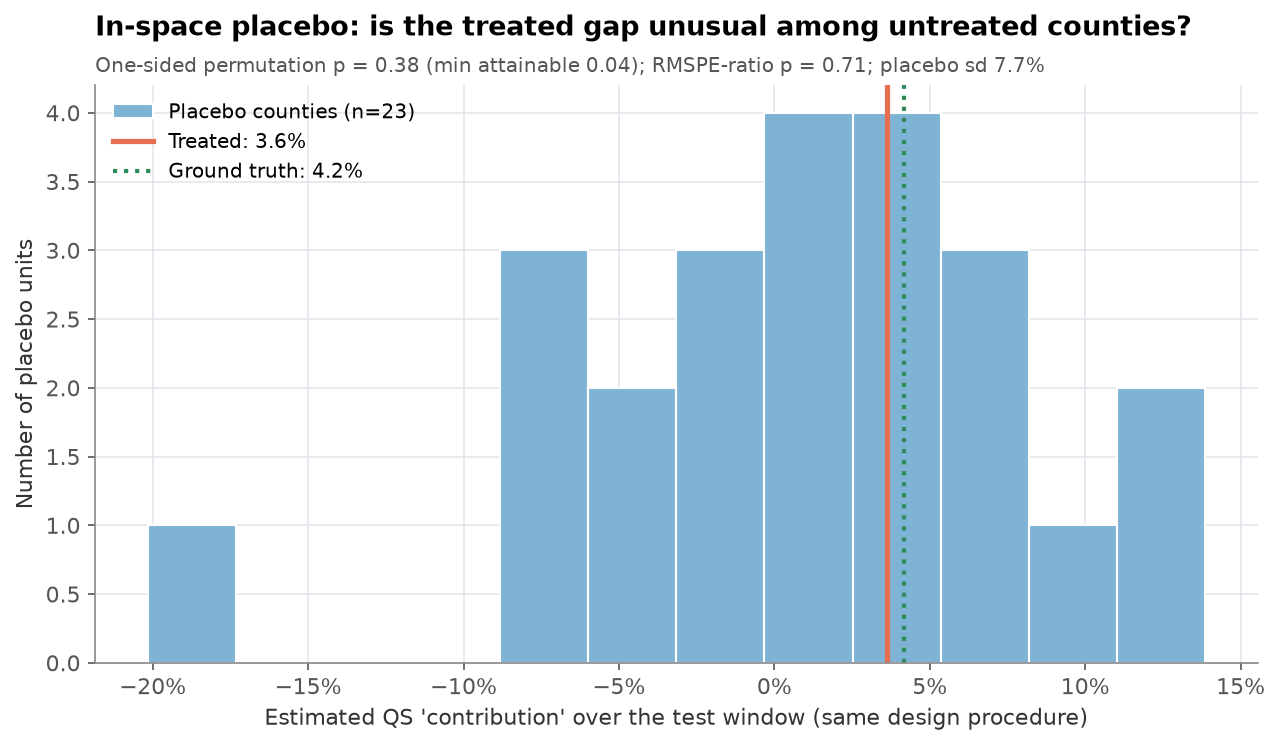

In [20]:
print({k: round(v["p_value_lift_one_sided"], 3) for k, v in S.placebo.items()},
      "| min attainable p", round(S.placebo["qs"]["min_attainable_p"], 3))
show("11_placebo_in_space", "meta")

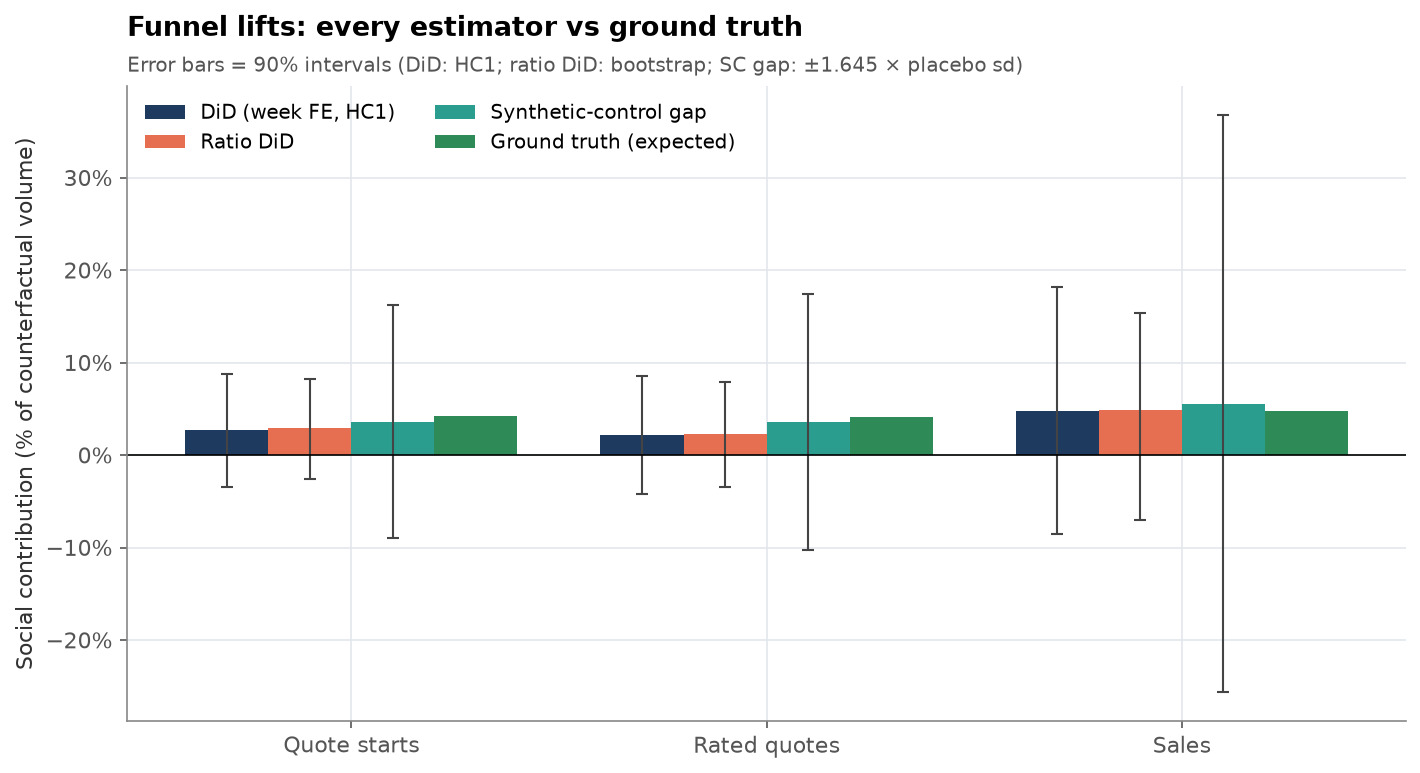

In [21]:
show("12_truth_vs_estimate", "meta")

## 7. Attribution vs incrementality, and what it costs
Last-touch over-claims Social quote starts several-fold (and under-claims sales, which bind later through other touchpoints).
Incremental cost per outcome is what should drive budget and feed the MMM calibration.

In [22]:
S.attribution

,stage,lt_share,measured_lift,lt_cost_per,incremental_cost_per,lt_per_1k,incremental_per_1k,overclaim_ratio
0,qs,0.2254,0.0268,15.4686,58.3396,64.6469,17.1410,3.7715
1,rated,0.1871,0.0220,29.8976,114.2088,33.4474,8.7559,3.8200
2,sales,0.0958,0.0481,638.2498,566.8614,1.5668,1.7641,0.8881


In [23]:
S.efficiency

,stage,blended_cost_per,incremental_cost_per,true_incremental_cost_per,ratio_to_blended,social_spend_share
0,qs,30.8713,58.3396,37.1900,1.8898,0.1432
1,rated,48.6591,114.2088,59.2227,2.3471,0.1432
2,sales,516.3502,566.8614,585.2137,1.0978,0.1432


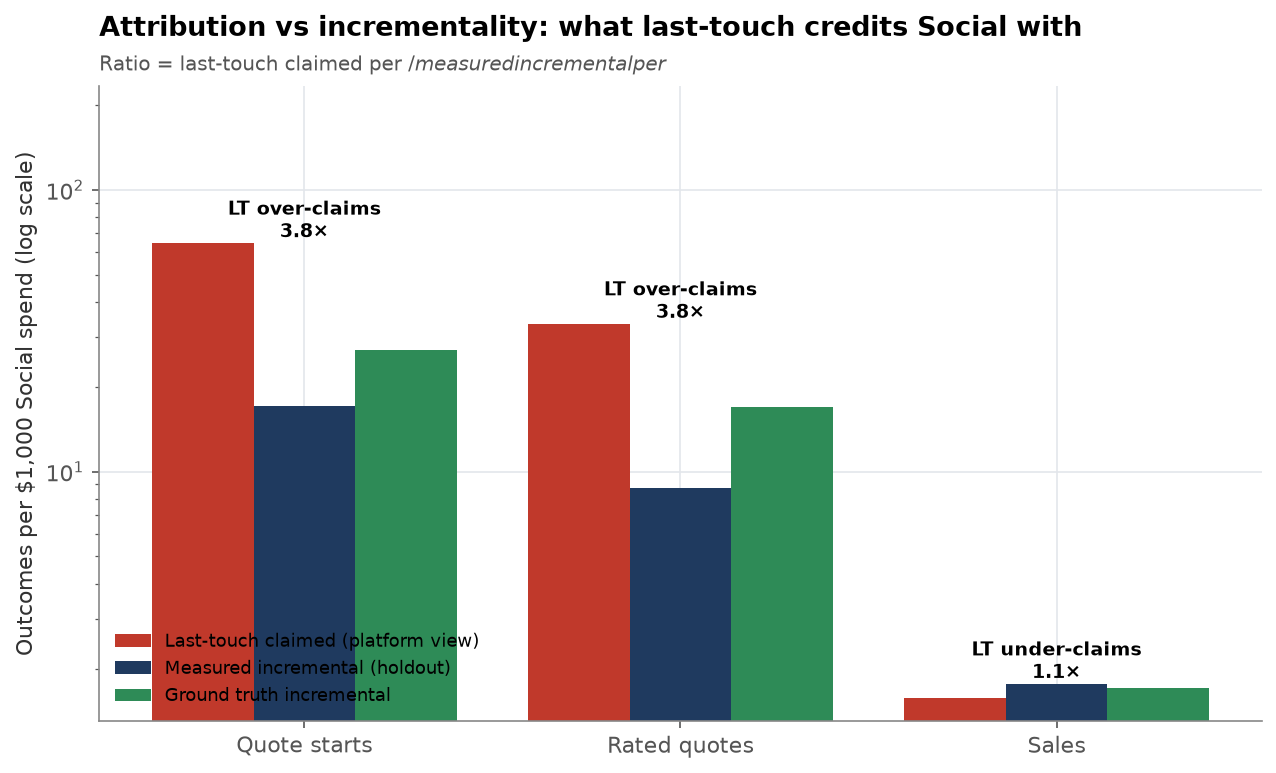

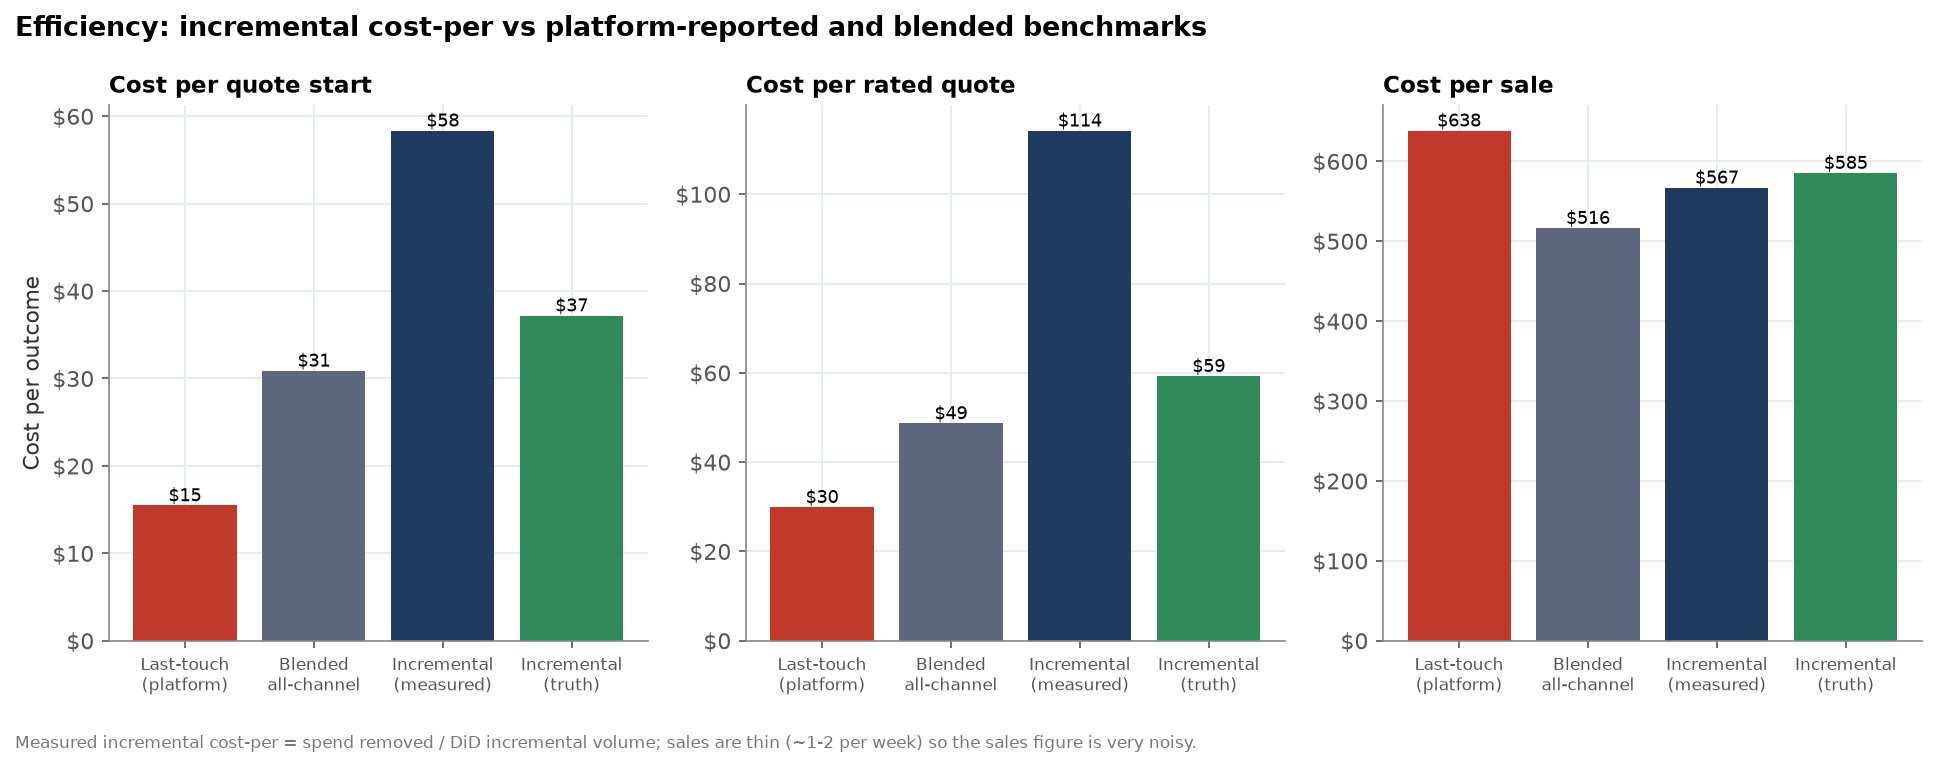

In [24]:
show("13_attribution_vs_incrementality", "meta"); show("14_cost_per_comparison", "meta")

In [25]:
ipd = MP.incremental_per_dollar(S)["social"]
print("MMM calibration input (incremental per $ of spend removed):")
print({k: round(ipd[k], 5) for k in ("qs", "rated", "sales", "sales_se", "sales_truth")})
print("Verdict:", S.verdict)

MMM calibration input (incremental per $ of spend removed):
{'qs': 0.01714, 'rated': 0.00876, 'sales': 0.00176, 'sales_se': 0.00299, 'sales_truth': 0.00171}
Verdict: {'label': 'directional', 'underpowered': True, 'design_mde_8wk': 0.10099579913979516, 'all_stages_positive': True}


## 8. Write outputs
Regenerates the figures, `reports/results/meta.json` (headline, estimates, design, validation, truth,
`extra.incremental_per_dollar`) and the exec readout `reports/readouts/meta.md`.

In [26]:
from incrlab.meta import figures as F, report
S.figures = F.make_all(S)
report.write_results_json(S); report.write_readout_md(S)
display(Markdown((ROOT / "reports/readouts/meta.md").read_text()))

# Social (Meta) geo holdout — readout

*Synthetic data; illustrative magnitudes. Generated by `python -m incrlab.meta`; every number below is in
`reports/results/meta.json`.*

**Verdict: DIRECTIONAL.** Pausing Social in Cinderford County + Netherby County cost an estimated **2.7% of quote
starts, 2.2% of rated quotes and 4.8% of sales** over 8
weeks (ground truth 4.2% / 4.2% /
4.7%). The direction is right, but no estimate is statistically distinguishable from zero
(QS p=0.45; placebo p=0.38).

## Question
If Social is switched off, how much quote, rated-quote and sales volume is actually lost — and how does that compare
with what last-touch attribution credits Social with?

## Design
- **Market:** Cinderford County + Netherby County (pop 594k), chosen by the pipeline from 25 candidate
  markets (single counties and contiguous 2–3 county bundles near 502k people);
  9 passed all hard filters (fit, max donor weight ≤ 50%, effective donors,
  donor count, injected-lift recovery); the top scorer also passed the leave-one-donor-out jackknife.
- **Control:** synthetic control of 11 Eastmoor counties, weights fit on weeks 0–50
  of the Social share of quote starts and **locked**; validated out-of-sample by injecting 5/10/15% losses into weeks
  51–57 (recovered 5.9%, 10.8%, 15.8%).
- **Test:** Social paused weeks 58–65 (8 weeks); 25% of
  BAU spend kept delivering (incomplete holdout), 75% removed ($7,847).
- **Primary estimator:** DiD of treated vs locked synthetic with week fixed effects and HC1 robust SE (HAC as a
  robustness check); cross-checked by a ratio DiD and the synthetic-control gap with an in-space placebo p-value.

## Result (contribution = volume lost without Social)
| Stage | DiD (week FE) | 90% CI | p | Ratio DiD | SC gap | Truth | Incremental, 8 wk |
|---|---|---|---|---|---|---|---|
| Quote starts | 2.7% | -3.4% to 8.8% | 0.45 | 2.9% | 3.6% | 4.2% | 135 (truth 211) |
| Rated quotes | 2.2% | -4.2% to 8.6% | 0.55 | 2.3% | 3.5% | 4.2% | 69 (truth 133) |
| Sales | 4.8% | -8.6% to 18.2% | 0.54 | 4.9% | 5.6% | 4.7% | 14 (truth 13) |

## Efficiency & attribution
| Stage | Last-touch cost-per | Incremental cost-per (measured) | Incremental cost-per (truth) | LT share of volume | LT claim vs incremental |
|---|---|---|---|---|---|
| Quote starts | $15 | $58 | $37 | 22.5% | 3.8x |
| Rated quotes | $30 | $114 | $59 | 18.7% | 3.8x |
| Sales | $638 | $567 | $585 | 9.6% | 0.9x |

Last-touch **over-credits** Social on quote starts and rated quotes and is closer to (or below) incrementality on
sales — Social influences buyers who later close through other channels.

## Confidence
- Design MDE for 8 weeks (80% power, one-sided α=0.1) is **10.1%**; the true
  effect is ~4%, so the test was **underpowered**
  . With weekly sales of ~34
  in the market, sales-level conclusions are especially noisy.
- Leakage (25% of spend still delivered) makes the measured loss a **lower bound** of a
  full pause; per-dollar figures use spend actually removed.

## Recommendation
1. Treat the result as **directional evidence that Social is incremental** — keep spend; do not cut on this read.
2. Use the per-dollar estimate (with its SE) only as a weak prior in the MMM; it is in `extra.incremental_per_dollar`.
3. Re-test with ≥12+ weeks or a multi-market design (2–3 matched holdout markets) and tighter delivery controls
   to get a decision-grade read; optimise to incremental cost per sale, not platform-reported cost per quote.


**Take-aways**
* The pipeline, not an analyst, chose the market; weights were locked before launch and validated with injected lifts.
* Estimators land near the true contribution, but with an 8-week, 25%-leaky holdout the 90% intervals include zero —
  the honest label is **directional**. The power curve shows how much longer (or cleaner) the test would need to be.
* Last-touch materially overstates Social's quote starts; the incremental cost per QS is a multiple of the last-touch view.